In [161]:
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html
#plt.style.use('bmh')
#plt.style.use('Solarize_Light2')
plt.style.use('ggplot')


In [162]:
results = pd.read_csv('/home/leveque/SYNC_CLOUDS/github/staketracker/analysis/detection_run/detection_results.csv',header=5)
results['creation_date']=pd.to_datetime(results['creation_date'])
#print('results',results.head(5))

reconyx = pd.read_csv('/home/leveque/SYNC_CLOUDS/github/staketracker/analysis/reconyx_data.csv')
reconyx['timestamp']=pd.to_datetime(reconyx_temp['timestamp'])
reconyx['timestamp_normalized']=pd.to_datetime(reconyx_temp['timestamp_normalized'])
#print('reconyx:',reconyx.head(5))

new_results = pd.concat([results, reconyx], axis=1)
new_results.drop(["original_file","new_file","creation_date","timestamp_normalized"],axis=1,inplace=True)
new_results.head(10)


,image,detected_pixels,balise_height_px,y_min,y_max,timestamp,temp_c,ts_worst_score,temp_worst_score,status,error
0,RCNX0001.JPG,198,27,353.0,379.0,2024-07-17 13:00:00,3,0.0759,0.3103,ok,NaN
1,RCNX0002.JPG,164,25,353.0,377.0,2024-07-17 14:00:00,3,0.0759,0.3103,ok,NaN
2,RCNX0003.JPG,249,30,352.0,381.0,2024-07-17 15:00:00,2,0.0759,0.3504,ok,NaN
3,RCNX0004.JPG,175,29,353.0,381.0,2024-07-17 16:00:00,2,0.0759,0.3504,ok,NaN
4,RCNX0005.JPG,160,26,353.0,378.0,2024-07-17 17:00:00,2,0.0759,0.3504,ok,NaN
5,RCNX0006.JPG,200,30,352.0,381.0,2024-07-17 18:00:00,1,0.0759,0.2567,ok,NaN
6,RCNX0007.JPG,186,27,351.0,377.0,2024-07-18 09:00:00,5,0.0759,0.3438,ok,NaN
7,RCNX0008.JPG,2595,87,343.0,429.0,2024-07-18 10:00:00,5,0.0759,0.3438,ok,NaN
8,RCNX0009.JPG,503,43,350.0,392.0,2024-07-18 11:00:00,6,0.0759,0.3147,ok,NaN
9,RCNX0010.JPG,680,43,350.0,392.0,2024-07-18 12:00:00,5,0.0759,0.3438,ok,NaN


In [170]:
meteo = pd.read_csv('/home/leveque/SYNC_CLOUDS/github/staketracker/analysis/weather_data_lat45.874_lon6.989_2024-07-17_to_2024-11-15.csv')
meteo["date"]=pd.to_datetime(meteo["date"])

from staketracker.weather_code import describe_weather
for i in range(meteo.shape[0]):
    print(i, meteo["weather_code"][i],describe_weather(meteo["weather_code"][i]))
#meteo

0 3.0 ☁️ Overcast
1 3.0 ☁️ Overcast
2 51.0 🌦️ Light drizzle
3 2.0 ⛅ Partly cloudy
4 53.0 🌦️ Moderate drizzle
5 3.0 ☁️ Overcast
6 3.0 ☁️ Overcast
7 51.0 🌦️ Light drizzle
8 3.0 ☁️ Overcast
9 51.0 🌦️ Light drizzle
10 3.0 ☁️ Overcast
11 3.0 ☁️ Overcast
12 1.0 🌤️ Mainly clear
13 3.0 ☁️ Overcast
14 63.0 🌧️ Moderate rain
15 55.0 🌧️ Dense drizzle
16 3.0 ☁️ Overcast
17 3.0 ☁️ Overcast
18 3.0 ☁️ Overcast
19 3.0 ☁️ Overcast
20 1.0 🌤️ Mainly clear
21 61.0 🌦️ Slight rain
22 3.0 ☁️ Overcast
23 3.0 ☁️ Overcast
24 3.0 ☁️ Overcast
25 3.0 ☁️ Overcast
26 3.0 ☁️ Overcast
27 63.0 🌧️ Moderate rain
28 53.0 🌦️ Moderate drizzle
29 3.0 ☁️ Overcast
30 3.0 ☁️ Overcast
31 55.0 🌧️ Dense drizzle
32 61.0 🌦️ Slight rain
33 51.0 🌦️ Light drizzle
34 3.0 ☁️ Overcast
35 3.0 ☁️ Overcast
36 3.0 ☁️ Overcast
37 0.0 ☀️ Clear sky
38 3.0 ☁️ Overcast
39 51.0 🌦️ Light drizzle
40 3.0 ☁️ Overcast
41 3.0 ☁️ Overcast
42 1.0 🌤️ Mainly clear
43 3.0 ☁️ Overcast
44 3.0 ☁️ Overcast
45 3.0 ☁️ Overcast
46 3.0 ☁️ Overcast
47 3.0 ☁️ Overcast
4

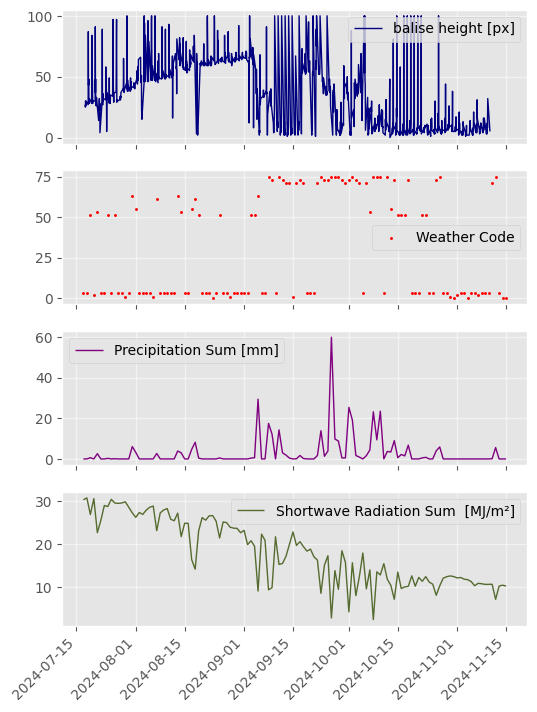

In [164]:
fig,ax = plt.subplots(4,sharex=True, figsize=(6, 8))
#fig.tight_layout

myFmt = mdates.DateFormatter('%Y-%m-%d')
plt.gca().xaxis.set_major_formatter(myFmt)
plt.xticks(rotation=45,ha='right')

ax[0].plot(new_results['timestamp'],new_results["balise_height_px"],color='navy',linewidth=1,label="balise height [px]")
#ax[0].set_ylabel('Balise height [pix]')
#ax[0].set_title('')
ax[0].legend()
#ax[0].ylabel

ax[1].scatter(meteo['date'],meteo["weather_code"],linewidth=1,label="Weather Code",s=1.2,color='red')
#ax[1].set_ylabel="weather code"
ax[1].legend()

ax[2].plot(meteo['date'],meteo['precipitation_sum'],linewidth=1,label="Precipitation Sum [mm]",color='purple')
#ax[2].set_ylabel="Precipitations [mm]"
ax[2].legend()

ax[3].plot(meteo['date'],meteo['shortwave_radiation_sum'],linewidth=1,label="Shortwave Radiation Sum  [MJ/m²]",color='darkolivegreen')
#ax[3].set_ylabel="shortwave radiation [MJ/m²]"
ax[3].legend()

In [171]:

new_results = new_results.assign(date = pd.to_datetime(new_results['timestamp'].dt.strftime("%Y-%m-%d")))
meteo['date'] = pd.to_datetime(meteo['date'].dt.strftime("%Y-%m-%d"))
meteo.head(5)


,date,weather_code,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,temperature_2m_mean,shortwave_radiation_sum,wind_direction_10m_dominant
0,2024-07-17,3.0,0.0,0.0,0.0,0.0,5.063917,30.33,309.34048
1,2024-07-18,3.0,0.0,0.0,0.0,0.0,6.355584,30.77,275.44022
2,2024-07-19,51.0,0.6,0.6,0.0,4.0,5.811834,26.91,301.71976
3,2024-07-20,2.0,0.0,0.0,0.0,0.0,6.403500,30.61,307.35504
4,2024-07-21,53.0,2.6,2.6,0.0,11.0,4.209751,22.70,140.52760


date                           datetime64[us]
weather_code                          float64
precipitation_sum                     float64
rain_sum                              float64
snowfall_sum                          float64
precipitation_hours                   float64
temperature_2m_mean                   float64
shortwave_radiation_sum               float64
wind_direction_10m_dominant           float64
dtype: object


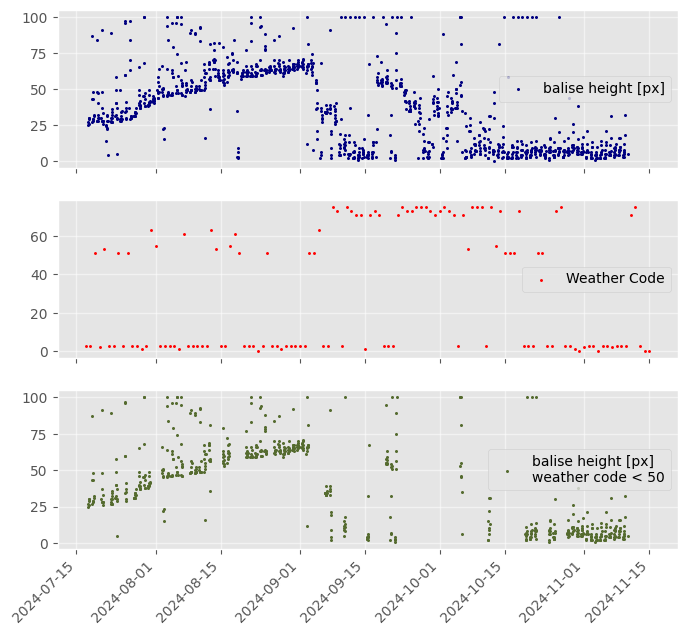

In [185]:

fig,ax = plt.subplots(3,sharex=True, figsize=(8, 7))
#fig.tight_layout

myFmt = mdates.DateFormatter('%Y-%m-%d')
plt.gca().xaxis.set_major_formatter(myFmt)
plt.xticks(rotation=45,ha='right')

ax[0].scatter(new_results['timestamp'],new_results["balise_height_px"],color='navy',linewidth=1,label="balise height [px]",s=1.4)
ax[0].legend()
#ax[0].ylabel
print(meteo.dtypes)

ax[1].scatter(meteo["date"],meteo["weather_code"],linewidth=1,label="Weather Code",s=1.2,color='red')
ax[1].legend()

# dates where the weather is OK
good_dates = meteo.loc[meteo["weather_code"] < 50, "date"]
#print(good_dates)

# keep only the rows of new_results that fall on those dates
mask = new_results["date"].isin(good_dates)
filtered = new_results[mask]
filtered.head(10)

ax[2].scatter(filtered["timestamp"],filtered["balise_height_px"],color='darkolivegreen',linewidth=1,label="balise height [px]"+"\n"+"weather code < 50",s=1.4)
ax[2].legend()

fig.savefig('test_meteo.png')
